In [6]:
import os
print(os.getcwd())


/Users/Sam/dc-allen-data-acquire/src/mapping/eeg_motifs


Matrix shape: (76, 10000) | Expected: (76, 10000)
All basic assertions passed.


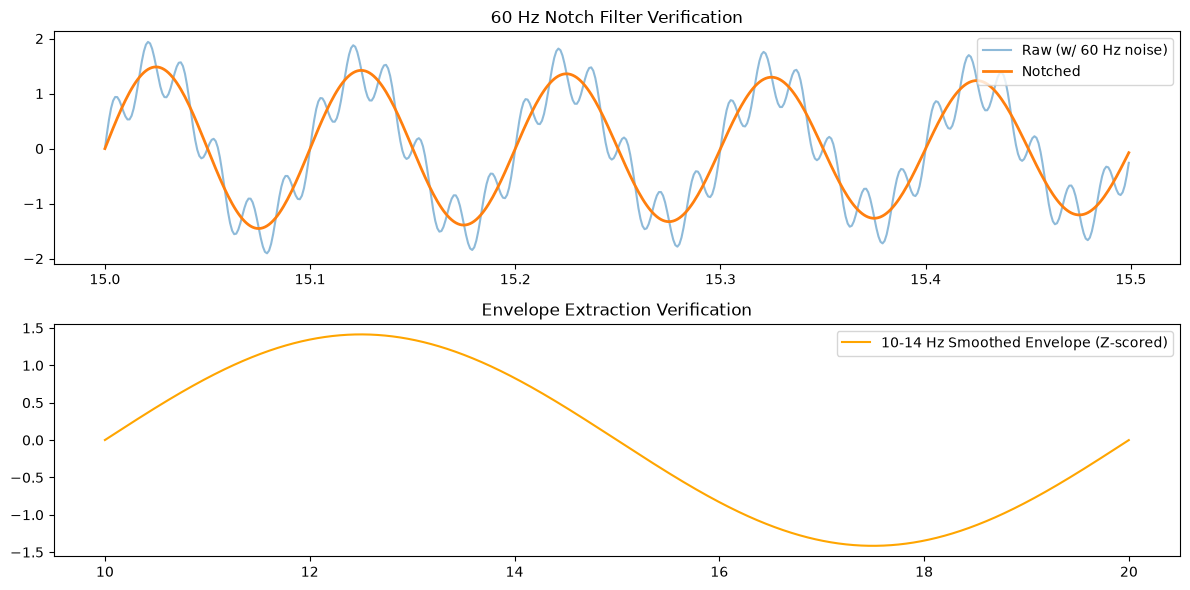

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat, loadmat
from preprocessing import apply_notch, smooth_env, FREQ_BANDS

# ---------------------------------------------------------
# 1. Create a Synthetic Test Signal
# ---------------------------------------------------------
fs = 1000.0  # 1000 Hz sampling rate
duration = 30.0  # 30 seconds to allow for 10s edge trimming
t = np.arange(int(duration * fs)) / fs

# Create a signal: 10 Hz carrier (target) + 60 Hz noise + slow modulation
freq_target = 10.0
freq_noise = 60.0
modulation = np.sin(2 * np.pi * 0.1 * t) + 1.5 # Slow 0.1 Hz amplitude modulation

# Combine into raw LFP
lfp_raw = modulation * np.sin(2 * np.pi * freq_target * t) + 0.5 * np.sin(2 * np.pi * freq_noise * t)

# ---------------------------------------------------------
# 2. Test the 60 Hz Notch Filter
# ---------------------------------------------------------
lfp_notched = apply_notch(lfp_raw, fs)

# ---------------------------------------------------------
# 3. Test smooth_env
# ---------------------------------------------------------
# We expect the 10 Hz band (index 9, since bands are 1-5, 2-6... 10-14 is index 9) 
# to capture the modulation envelope best.
smooth_matrix = smooth_env(lfp_notched, fs, bands=FREQ_BANDS, trim_edges=True)

# ---------------------------------------------------------
# 4. Assertions (Basic Sanity Checks)
# ---------------------------------------------------------
expected_length = int(duration * fs) - 2 * int(10.0 * fs) # 30s - 20s = 10s

print(f"Matrix shape: {smooth_matrix.shape} | Expected: (76, {expected_length})")
assert smooth_matrix.shape == (76, expected_length), "Dimension mismatch."
assert not np.any(np.isnan(smooth_matrix)), "NaNs leaked into the final output."
assert np.allclose(np.var(smooth_matrix, axis=1, ddof=1), 1.0), "Variance is not 1."
assert np.allclose(np.mean(smooth_matrix, axis=1), 0.0, atol=1e-5), "Mean is not 0."
print("All basic assertions passed.")

# ---------------------------------------------------------
# 5. Visual Verification
# ---------------------------------------------------------
plt.figure(figsize=(12, 6))

# Plot a small slice of the raw vs notched signal
plt.subplot(2, 1, 1)
slice_idx = slice(15000, 15500) # Look at the middle of the signal
plt.plot(t[slice_idx], lfp_raw[slice_idx], label='Raw (w/ 60 Hz noise)', alpha=0.5)
plt.plot(t[slice_idx], lfp_notched[slice_idx], label='Notched', linewidth=2)
plt.title("60 Hz Notch Filter Verification")
plt.legend()

# Plot the envelope of a relevant band
plt.subplot(2, 1, 2)
# Align time vector with the trimmed output
t_trimmed = t[int(10*fs):-int(10*fs)]
target_band_idx = 9 # Band 10-14 Hz, containing our 10 Hz carrier
plt.plot(t_trimmed, smooth_matrix[target_band_idx, :], label='10-14 Hz Smoothed Envelope (Z-scored)', color='orange')
plt.title("Envelope Extraction Verification")
plt.legend()

plt.tight_layout()
plt.show()

generate_shifts assertions passed.
get_motifs assertions passed. Recovered 1 canonical motif pairs.


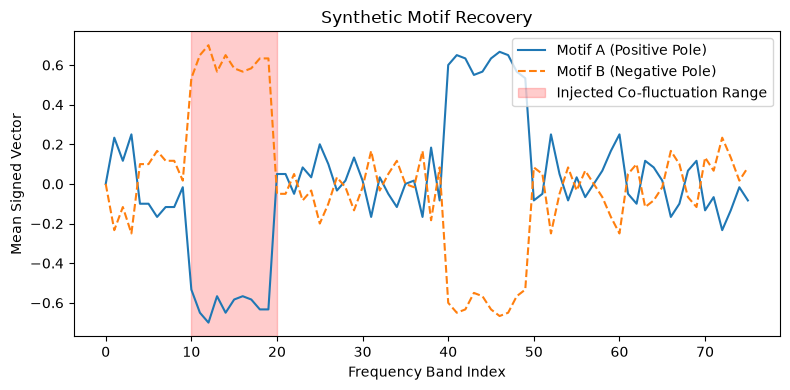

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from motif_discovery import generate_shifts, get_motifs

# ---------------------------------------------------------
# 1. Test generate_shifts
# ---------------------------------------------------------
# The null model requires shifting frequencies independently by multiples of 20 seconds.
fs = 1000.0
n_bands = 76
n_shifts = 20

shifts = generate_shifts(n_bands, fs, n_shifts)

assert shifts.shape == (n_bands, n_shifts + 1), "Shift matrix shape is incorrect."
assert np.all(shifts[:, 0] == 0), "First shift column must be strictly zero (unshifted real data)."
print("generate_shifts assertions passed.")

# ---------------------------------------------------------
# 2. Test get_motifs with Synthetic Data
# ---------------------------------------------------------
n_samples = 60000
n_bands = 76
fs = 1000.0

# Generate random background noise
session_1 = np.random.randn(n_bands, n_samples)
session_2 = np.random.randn(n_bands, n_samples)

# Inject a massive, undeniable synthetic motif:
# Make bands 10-20 strongly positive and 40-50 strongly negative
# Present for 30 consecutive seconds (50% of the recording)
session_1[10:20, 15000:45000] = 5.0 
session_1[40:50, 15000:45000] = -5.0 

session_2[10:20, 15000:45000] = 5.0 
session_2[40:50, 15000:45000] = -5.0 

lfp_sessions = [session_1, session_2]

from motif_discovery import get_motifs
# We use fewer shifts (e.g., 5) just to speed up the test execution
final_motifs = get_motifs(lfp_sessions, fs, num_shifts=5)

assert final_motifs.shape[0] == n_bands, "Motif templates must match the number of input frequency bands."
assert final_motifs.shape[1] % 2 == 0, "Motifs must be paired with their exact sign-inverted counterparts."
print(f"get_motifs assertions passed. Recovered {final_motifs.shape[1] // 2} canonical motif pairs.")

# ---------------------------------------------------------
# 3. Visual Verification
# ---------------------------------------------------------
if final_motifs.shape[1] > 0:
    plt.figure(figsize=(8, 4))
    plt.plot(final_motifs[:, 0], label='Motif A (Positive Pole)')
    plt.plot(final_motifs[:, 1], label='Motif B (Negative Pole)', linestyle='--')
    plt.axvspan(10, 20, color='red', alpha=0.2, label='Injected Co-fluctuation Range')
    plt.title("Synthetic Motif Recovery")
    plt.xlabel("Frequency Band Index")
    plt.ylabel("Mean Signed Vector")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [3]:
from pynwb import NWBHDF5IO
from pathlib import Path

from pathlib import Path

# Relative path from your current working directory (e.g., notebook location)
# Steps up to the repo root (/Users/Sam/dc-allen-data-acquire/) regardless of where you start the notebook
repo_root = Path.cwd().resolve()
while repo_root.name != "dc-allen-data-acquire" and repo_root.parent != repo_root:
    repo_root = repo_root.parent

data_dir = repo_root / "data" / "raw"

# Safely grab the first .nwb file found
nwb_files = sorted(list(data_dir.glob("*.nwb")))
if not nwb_files:
    raise FileNotFoundError(f"No .nwb files found in {data_dir.resolve()}")

test_file = nwb_files[0]
print(f"Loaded test file: {test_file}")

with NWBHDF5IO(test_file, mode='r') as io:
    nwbfile = io.read()
    df = nwbfile.electrodes.to_dataframe()

# Filter for the EEG array group
eeg_df = df[df['group_name'] == 'EEG array']

print("Columns in electrodes table:", list(df.columns))
print("Unique locations in EEG array:\n", eeg_df['location'].unique())
display(eeg_df.head(10))

Loaded test file: /Users/Sam/dc-allen-data-acquire/data/raw/688277-20230921-v001.nwb


Columns in electrodes table: ['location', 'group', 'is_data_valid', 'probe_vertical_position', 'probe_horizontal_position', 'group_name', 'x', 'y', 'z', 'reference']
Unique locations in EEG array:
 <StringArray>
['VISl', 'VISp', 'RSPagl', 'VISal', 'SSp-bfd', 'VISa', 'SSp-ll', 'MOp', 'MOs']
Length: 9, dtype: str


,location,group,is_data_valid,probe_vertical_position,probe_horizontal_position,group_name,x,y,z,reference
id,,,,,,,,,,
0,VISl,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,377.0,58.0,82.0,"stainless steel skull screw, mid CB"
1,VISp,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,377.0,24.0,141.0,"stainless steel skull screw, mid CB"
2,RSPagl,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,377.0,20.0,188.0,"stainless steel skull screw, mid CB"
3,VISal,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,333.0,47.0,79.0,"stainless steel skull screw, mid CB"
4,VISp,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,333.0,25.0,119.0,"stainless steel skull screw, mid CB"
5,RSPagl,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,333.0,7.0,182.0,"stainless steel skull screw, mid CB"
6,SSp-bfd,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,290.0,47.0,81.0,"stainless steel skull screw, mid CB"
7,VISa,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,290.0,26.0,119.0,"stainless steel skull screw, mid CB"
8,RSPagl,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,290.0,9.0,183.0,"stainless steel skull screw, mid CB"


In [4]:
import numpy as np
from scipy import signal
from preprocessing import load_eeg_trace

# ---------------------------------------------------------
# 1. Verify Band 76 Filter Stability at 500 Hz
# ---------------------------------------------------------
# The highest frequency band is 76-80 Hz. We extract the poles (p) directly 
# using the zero-pole-gain (zpk) output format.
z, p, k = signal.butter(6, [76.0, 80.0], btype='bandpass', fs=500.0, output='zpk')

# For a stable IIR filter, all poles must lie strictly inside the unit circle (magnitude < 1.0)
max_pole_magnitude = np.max(np.abs(p))
is_stable = max_pole_magnitude < 1.0

print(f"Maximum pole magnitude: {max_pole_magnitude:.6f}")
print(f"Filter stability check (76-80 Hz at 500 Hz fs): {is_stable}")
assert is_stable, "Filter is unstable! Poles lie outside or on the unit circle."

# ---------------------------------------------------------
# 2. Verify Decimation and Temporal Hop Logic
# ---------------------------------------------------------
# load_eeg_trace now defaults to target_fs=500.0
# Ensure 'test_file' is defined from your earlier notebook cells
eeg_data, actual_fs = load_eeg_trace(test_file, electrode_label='Fz')

print(f"\nOriginal downsampled fs: {actual_fs:.2f} Hz")
assert actual_fs <= 500.0, f"Decimation failed, actual fs is {actual_fs}"

# Verify the temporal hop calculation exactly as it appears in motif_discovery.py
hop = int(np.round(actual_fs))
print(f"Calculated hop size: {hop} samples")

# A 60-second slice should yield exactly 60 downsampled points
slice_len = int(60 * actual_fs)
simulated_motif_input = np.ones((76, slice_len))
downsampled_input = simulated_motif_input[:, ::hop]

print(f"Points per 60 seconds after hop: {downsampled_input.shape[1]}")
assert downsampled_input.shape[1] == 60, "Temporal hop is not correctly extracting 1 Hz bins."
print("All decimation and stability checks passed.")

Maximum pole magnitude: 0.993624
Filter stability check (76-80 Hz at 500 Hz fs): True

Original downsampled fs: 500.00 Hz
Calculated hop size: 500 samples
Points per 60 seconds after hop: 60
All decimation and stability checks passed.


In [5]:
import time
import numpy as np
from pynwb import NWBHDF5IO
from preprocessing import load_eeg_trace, apply_notch, smooth_env

# 1. Load just 60 seconds
with NWBHDF5IO(test_file, mode='r') as io:
    nwbfile = io.read()
    eeg_series = nwbfile.acquisition['ElectricalSeriesEEG']
    
    # Correctly handle the sampling rate
    if eeg_series.rate is not None:
        fs = eeg_series.rate
    else:
        # Calculate from the difference between the first 1000 timestamps
        fs = 1.0 / np.median(np.diff(eeg_series.timestamps[:1000]))
        
    print(f"Sampling frequency: {fs:.2f} Hz")
    
    # Take first 60 seconds of channel 0
    slice_len = int(60 * fs)
    test_raw = eeg_series.data[:slice_len, 0] * eeg_series.conversion

# 2. Benchmark processing
t0 = time.time()
notched = apply_notch(test_raw, fs)
smoothed = smooth_env(notched, fs, trim_edges=True)
elapsed = time.time() - t0

print(f"60s slice processed in: {elapsed:.2f} seconds")
print(f"Extrapolated full run (~3 hours of data): {(elapsed / 60) * (len(eeg_series.data) / fs) / 60:.1f} minutes per session")
print("Output shape:", smoothed.shape)
assert np.all(np.isfinite(smoothed)), "Output contains NaNs or Infs!"

Sampling frequency: 2499.99 Hz
60s slice processed in: 123.52 seconds
Extrapolated full run (~3 hours of data): 158.3 minutes per session
Output shape: (76, 99999)


In [6]:
import time
import numpy as np
from scipy import signal
from scipy.fft import next_fast_len
from pynwb import NWBHDF5IO

# 1. Pull 60s directly from the file at 2500 Hz
with NWBHDF5IO(test_file, mode='r') as io:
    nwbfile = io.read()
    eeg_series = nwbfile.acquisition['ElectricalSeriesEEG']
    raw_fs = float(eeg_series.rate or 2500.0)
    slice_len_raw = int(60 * raw_fs)
    raw_slice = np.asarray(eeg_series.data[:slice_len_raw, 0], dtype=np.float64) * float(eeg_series.conversion)

# 2. Downsample: 2500 Hz -> 500 Hz (factor of 5)
q = int(round(raw_fs / 500.0))
fs_500 = raw_fs / q
decimated_slice = signal.decimate(raw_slice, q, ftype='iir', zero_phase=True)

print(f"Decimated Sampling Frequency: {fs_500:.2f} Hz")
print(f"Input samples (60s): {len(decimated_slice)}")

# 3. Benchmark with next_fast_len enabled
bands = np.column_stack([np.arange(1, 77), np.arange(5, 81)])
n_samples = len(decimated_slice)
n_fft = next_fast_len(n_samples)

# 5s Gaussian window
M = int(round(5.0 * fs_500))
w_gamma = signal.windows.gaussian(M, std=(M - 1) / 2.0)
w_gamma /= w_gamma.sum()

t0 = time.time()

# 60 Hz Notch
sos_notch = signal.butter(6, [59.0, 61.0], btype='bandstop', fs=fs_500, output='sos')
notched = signal.sosfiltfilt(sos_notch, decimated_slice)

# 76-band filtering + fast Hilbert + smoothing
smooth_matrix = np.zeros((76, n_samples), dtype=np.float32)
for i in range(76):
    sos = signal.butter(6, [float(bands[i, 0]), float(bands[i, 1])], btype='bandpass', fs=fs_500, output='sos')
    filt = signal.sosfiltfilt(sos, notched)
    env = np.abs(signal.hilbert(filt, N=n_fft)[:n_samples])
    smooth_matrix[i, :] = signal.filtfilt(w_gamma, [1.0], env).astype(np.float32)

# 10s edge trimming
edge = int(round(10.0 * fs_500))
smooth_matrix = smooth_matrix[:, edge:-edge]
mu = np.mean(smooth_matrix, axis=1, keepdims=True)
sigma = np.std(smooth_matrix, axis=1, ddof=1, keepdims=True)
smooth_matrix = (smooth_matrix - mu) / sigma

elapsed = time.time() - t0

print(f"\nExecution time at 500 Hz: {elapsed:.2f} seconds")
print(f"Output shape: {smooth_matrix.shape} (Expected: (76, 19999))")
print(f"Extrapolated 3-hour session: {(elapsed / 60) * (3 * 3600 / 60):.1f} minutes")

Decimated Sampling Frequency: 500.00 Hz
Input samples (60s): 30000

Execution time at 500 Hz: 8.73 seconds
Output shape: (76, 20000) (Expected: (76, 19999))
Extrapolated 3-hour session: 26.2 minutes


In [10]:
print(f"Extracted fs: {fs} Hz")
print(f"Downsampled timepoints per session: {int(len(eeg_series.data) / fs)}")
assert fs > 100, f"Unusually low fs ({fs}) detected; verify rate vs interval logic."

Extracted fs: 2499.9915229488706 Hz
Downsampled timepoints per session: 4613


In [ ]:
# Run the heavy functions
eeg_data = load_eeg_trace(...)
band_matrix = smooth_env(...)
motifs = get_motifs(...)

# Use the notebook just for what it does best: plotting
plt.plot(motifs)
plt.show()